In [30]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
from pathlib import Path

data_dir = Path("../data")

train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")

In [32]:
display(train.head())

,id,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,6KwkVtXm8OUp2XffN5k7lY,Hillsong Worship,No Other Name,No Other Name,50,440247,False,0.369,0.598,...,-6.984,1,0.0304,0.00511,0.000000,0.176,0.0466,148.014,4,world-music
1,1,2dp5I5MJ8bQQHDoFaNRFtX,Internal Rot,Grieving Birth,Failed Organum,11,93933,False,0.171,0.997,...,-3.586,1,0.1180,0.00521,0.801000,0.420,0.0294,122.223,4,grindcore
2,2,5avw06usmFkFrPjX8NxC40,Zhoobin Askarieh;Ali Sasha,Noise A Noise 20.4-1,"Save the Trees, Pt. 1",0,213578,False,0.173,0.803,...,-10.071,0,0.1440,0.61300,0.001910,0.195,0.0887,75.564,3,iranian
3,3,75hT0hvlESnDJstem0JgyR,Bryan Adams,All I Want For Christmas Is You,Merry Christmas,0,151387,False,0.683,0.511,...,-5.598,1,0.0279,0.40600,0.000197,0.111,0.5980,109.991,3,rock
4,4,4bY2oZGA5Br3pTE1Jd1IfY,Nogizaka46,バレッタ TypeD,月の大きさ,57,236293,False,0.555,0.941,...,-3.294,0,0.0481,0.48400,0.000000,0.266,0.8130,92.487,4,j-idol


In [33]:
print(f"Dimensions test: {test.shape[0]} lignes, {test.shape[1]} colonnes")
print(f"Dimensions train: {train.shape[0]} lignes, {train.shape[1]} colonnes")

Dimensions test: 22800 lignes, 20 colonnes
Dimensions train: 91200 lignes, 21 colonnes


In [34]:
print("\n--- Informations sur les colonnes ---")
test.info()
train.info()


--- Informations sur les colonnes ---
<class 'pandas.DataFrame'>
RangeIndex: 22800 entries, 0 to 22799
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                22800 non-null  int64  
 1   track_id          22800 non-null  str    
 2   artists           22800 non-null  str    
 3   album_name        22800 non-null  str    
 4   track_name        22800 non-null  str    
 5   duration_ms       22800 non-null  int64  
 6   explicit          22800 non-null  bool   
 7   danceability      22800 non-null  float64
 8   energy            22800 non-null  float64
 9   key               22800 non-null  int64  
 10  loudness          22800 non-null  float64
 11  mode              22800 non-null  int64  
 12  speechiness       22800 non-null  float64
 13  acousticness      22800 non-null  float64
 14  instrumentalness  22800 non-null  float64
 15  liveness          22800 non-null  float64
 16  valence     

In [35]:
# 1. Vérification des valeurs manquantes (nombre et pourcentage)
missing = pd.DataFrame({
    'Manquants train': train.isna().sum(),
    'Manquants test': test.isna().sum(),

    'Pourcentage train (%)': (train.isna().mean() * 100).round(2),
    'Pourcentage test (%)': (test.isna().mean() * 100).round(2)

})
print("--- Valeurs manquantes ---")
display(missing[missing['Manquants train'] > 0])
display(missing[missing['Manquants test'] > 0])


# 2. Détection des doublons stricts
print(f"Nombre de lignes doublonnées : {train.duplicated().sum()}")
print(f"Nombre de lignes doublonnées : {test.duplicated().sum()}")


# 3. Nombre de valeurs uniques par colonne
print("\n--- Valeurs uniques par colonne ---")
print(train.nunique())
print(test.nunique())

--- Valeurs manquantes ---


,Manquants train,Manquants test,Pourcentage train (%),Pourcentage test (%)


,Manquants train,Manquants test,Pourcentage train (%),Pourcentage test (%)


Nombre de lignes doublonnées : 0
Nombre de lignes doublonnées : 0

--- Valeurs uniques par colonne ---
id                  91200
track_id            74637
artists             27758
album_name          40565
track_name          61953
popularity            101
duration_ms         44448
explicit                2
danceability         1124
energy               2012
key                    12
loudness            18253
mode                    2
speechiness          1461
acousticness         4937
instrumentalness     5310
liveness             1704
valence              1761
tempo               40270
time_signature          5
track_genre           114
dtype: int64
id                  22800
track_id            21529
artists             11740
album_name          15179
track_name          19376
duration_ms         16682
explicit                2
danceability          967
energy               1402
key                    12
loudness            10875
mode                    2
speechiness          1299


In [36]:
# Variables numériques : moyenne, écart-type, quartiles, min/max
print("--- Variables Numériques ---")
display(train.describe().T)

# Variables catégorielles ou textuelles
print("\n--- Variables Catégorielles ---")
display(test.describe(include=['object', 'category']).T)

--- Variables Numériques ---


,count,mean,std,min,25%,50%,75%,max
id,91200.0,45599.500000,26327.316612,0.000,22799.7500,45599.500000,68399.2500,91199.000
popularity,91200.0,33.207094,22.301157,0.000,17.0000,34.000000,50.0000,100.000
duration_ms,91200.0,228088.034375,108922.056115,0.000,173946.0000,212760.000000,261519.0000,5237295.000
danceability,91200.0,0.566784,0.173448,0.000,0.4560,0.580000,0.6940,0.985
energy,91200.0,0.641224,0.251510,0.000,0.4720,0.684000,0.8530,1.000
key,91200.0,5.308443,3.559683,0.000,2.0000,5.000000,8.0000,11.000
loudness,91200.0,-8.262929,5.026228,-49.531,-10.0320,-7.012000,-5.0040,4.532
mode,91200.0,0.637741,0.480656,0.000,0.0000,1.000000,1.0000,1.000
speechiness,91200.0,0.084742,0.106122,0.000,0.0359,0.048900,0.0846,0.965
acousticness,91200.0,0.314997,0.332579,0.000,0.0170,0.169000,0.5970,0.996



--- Variables Catégorielles ---


C:\Users\noede\AppData\Local\Temp\ipykernel_12216\843473355.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(test.describe(include=['object', 'category']).T)


,count,unique,top,freq
track_id,22800,21529,5TXzVBQj31PD1YIS2Ll1mp,4
artists,22800,11740,The Beatles,64
album_name,22800,15179,Feliz Cumpleaños con Perreo,39
track_name,22800,19376,Run Rudolph Run,37
track_genre,22800,114,r-n-b,231


C:\Users\noede\AppData\Local\Temp\ipykernel_12216\538159886.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = train.select_dtypes(include=['object', 'category']).columns
C:\Users\noede\AppData\Local\Temp\ipykernel_12216\538159886.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train, x=col, order=train[col].value_counts().index, palette='viridis')


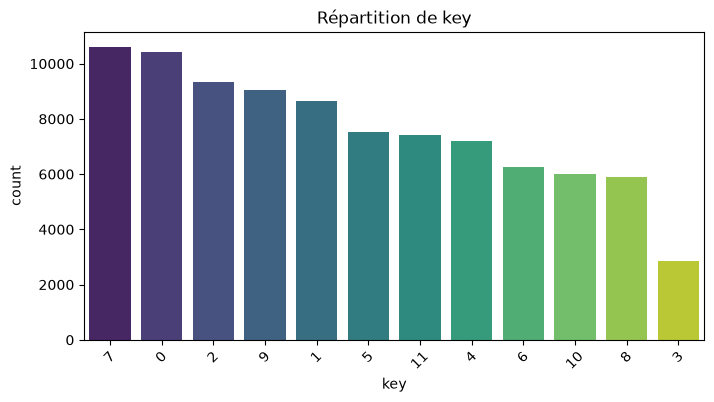

C:\Users\noede\AppData\Local\Temp\ipykernel_12216\538159886.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train, x=col, order=train[col].value_counts().index, palette='viridis')


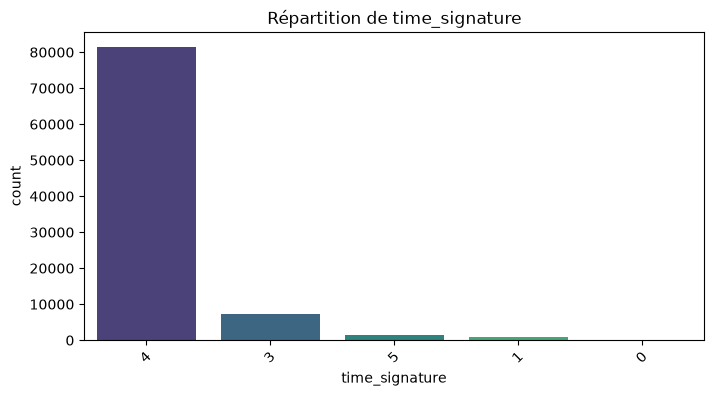

C:\Users\noede\AppData\Local\Temp\ipykernel_12216\538159886.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train, x=col, order=train[col].value_counts().index, palette='viridis')


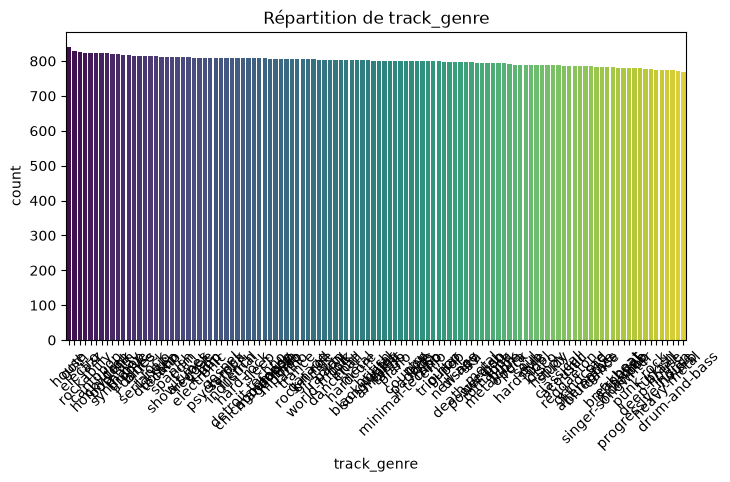

In [37]:
# 2. Répartition des variables catégorielles principales
train['key'] = train['key'].astype('category')
train['time_signature'] = train['time_signature'].astype('category')
cat_cols = train.select_dtypes(include=['object', 'category']).columns

for col in cat_cols:
    if train[col].nunique() <= 500:  # Limiter aux colonnes avec peu de catégories
        plt.figure(figsize=(8, 4))
        sns.countplot(data=train, x=col, order=train[col].value_counts().index, palette='viridis')
        plt.title(f'Répartition de {col}')
        plt.xticks(rotation=45)
        plt.show()

Index(['track_id', 'artists', 'album_name', 'track_name', 'key',
       'time_signature', 'track_genre'],
      dtype='str')
